In [279]:
import numpy as np
import cv2
from matplotlib import pyplot as plt

In [280]:

# Instantiate CLAHE once globally or inside the function
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def normalize_frame_pair(left_frame, right_frame):
    
    # 2. Apply CLAHE to equalize local lighting/contrast
    left_clahe = clahe.apply(left_frame)
    right_clahe = clahe.apply(right_frame)
    
    # 3. Quantitative Brightness Check (Mean pixel intensity)
    mean_left = np.mean(left_clahe)
    mean_right = np.mean(right_clahe)
    
    # Optional scalar adjustment if a residual global offset remains
    brightness_diff = mean_left - mean_right
    if abs(brightness_diff) > 5.0:  # Threshold for minor correction
        if brightness_diff > 0:
            right_clahe = cv2.add(right_clahe, int(abs(brightness_diff)))
        else:
            left_clahe = cv2.add(left_clahe, int(abs(brightness_diff)))

    # 4. Stack side-by-side for visual inspection
    combined_view = cv2.hconcat([left_clahe, right_clahe])
    return combined_view, left_clahe, right_clahe

# Example live loop integration:
# cap_left and cap_right are your camera streams
# ret_l, left_frame = cap_left.read()
# ret_r, right_frame = cap_right.read()
# if ret_l and ret_r:
#     preview, left_norm, right_norm = normalize_frame_pair(left_frame, right_frame)
#     cv2.imshow("Normalized Stereo Feed (Left | Right)", preview)

Text(0.5, 1.0, 'fixed right')

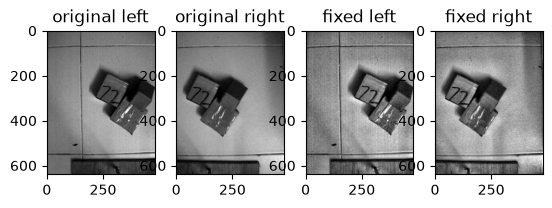

In [281]:
imgL = cv2.imread('dataset/214_left.jpg', cv2.IMREAD_GRAYSCALE)
imgR = cv2.imread('dataset/214_right.jpg', cv2.IMREAD_GRAYSCALE)
imgL = cv2.rotate(imgL, cv2.ROTATE_90_COUNTERCLOCKWISE)
imgR = cv2.rotate(imgR, cv2.ROTATE_90_COUNTERCLOCKWISE)
o_imgL, o_imgR = imgL, imgR
combined, imgL, imgR = normalize_frame_pair(imgL, imgR)
fig, ax = plt.subplots(1, 4)
ax[0].imshow(o_imgL, cmap='grey')
ax[0].set_title("original left")
ax[2].imshow(imgL, cmap='grey')
ax[2].set_title("fixed left")
ax[1].imshow(o_imgR, cmap='grey')
ax[1].set_title("original right")
ax[3].imshow(imgR, cmap='grey')
ax[3].set_title("fixed right")

In [282]:
# Load saved calibration parameters (maps and Q matrix)
data = np.load("stereo_calibration_params.npz")
map1_l, map2_l = data["map1_l"], data["map2_l"]
map1_r, map2_r = data["map1_r"], data["map2_r"]
Q = data["Q"]  # Disparity-to-depth mapping matrix

# --- Initialize StereoSGBM Matcher ---
# Note: numDisparities must be divisible by 16. Adjust based on your resolution (e.g., 32 or 64).
min_disp = 0
num_disp = 16  
block_size = 1

left_matcher = cv2.StereoSGBM_create(
    minDisparity=min_disp,
    numDisparities=num_disp,
    blockSize=block_size,
    P1=8 * 3 * block_size**2,     # Smoothness penalty for small disparity changes
    P2=32 * 3 * block_size**2,    # Smoothness penalty for large disparity changes
    disp12MaxDiff=1,
    uniquenessRatio=2,           # Margin in % by which the best match must surpass the second-best
    speckleWindowSize=100,        # Maximum size of smooth regions to consider noise speckles
    speckleRange=32,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)

def compute_depth_map(frame_l, frame_r):
    # 1. Remap (Rectify) raw frames
    rectified_l = cv2.remap(frame_l, map1_l, map2_l, cv2.INTER_LINEAR)
    rectified_r = cv2.remap(frame_r, map1_r, map2_r, cv2.INTER_LINEAR)
    
    # Optional: Convert to grayscale if not already done in Step 1
    

    # 2. Compute raw disparity map (returns 16-bit fixed-point image scaled by 16)
    disparity_SGBM = left_matcher.compute(rectified_l, rectified_r)

    # 3. Normalize disparity for visual display (scale back to float32)
    disparity_float = disparity_SGBM.astype(np.float32) / 16.0
    disparity_normalized = cv2.normalize(
        disparity_float, None, alpha=0, beta=255, 
        norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U
    )
    
    # Apply a colormap for real-time visualization
    depth_colormap = cv2.applyColorMap(disparity_normalized, cv2.COLORMAP_JET)

    # 4. Reproject to 3D point cloud / depth map in meters (optional)
    # 3D points shape: (Height, Width, 3) representing (X, Y, Z) coordinates
    points_3d = cv2.reprojectImageTo3D(disparity_float, Q)

    return depth_colormap, disparity_float, points_3d

In [283]:
calib_file = 'stereo_calibration_params.npz'

# Load your saved stereo calibration data
calib_data = np.load(calib_file)

# Extract your exact keys
mtx_l = calib_data['mtx_l']   
dist_l = calib_data['dist_l'] 
mtx_r = calib_data['mtx_r']   
dist_r = calib_data['dist_r'] 
R = calib_data['R']         
T = calib_data['T']         
imgL_rot = cv2.rotate(o_imgL, cv2.ROTATE_90_COUNTERCLOCKWISE)
imgR_rot = cv2.rotate(o_imgR, cv2.ROTATE_90_COUNTERCLOCKWISE)
h, w = o_imgL.shape[:2]

# 3. COMPUTE RECTIFICATION MAPS
R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(mtx_l, dist_l, mtx_r, dist_r, (w, h), R, T, alpha=0)

mapLx, mapLy = cv2.initUndistortRectifyMap(mtx_l, dist_l, R1, P1, (w, h), cv2.CV_32FC1)
mapRx, mapRy = cv2.initUndistortRectifyMap(mtx_r, dist_r, R2, P2, (w, h), cv2.CV_32FC1)

def new_compute_depth_map(frame_l, frame_r):
    # 1. Remap (Rectify) raw frames
    rectified_l = cv2.remap(frame_l, mapLx, mapLy, cv2.INTER_LINEAR)
    rectified_r = cv2.remap(frame_r, mapRx, mapRy, cv2.INTER_LINEAR)
    
    # Optional: Convert to grayscale if not already done in Step 1
    

    # 2. Compute raw disparity map (returns 16-bit fixed-point image scaled by 16)
    disparity_SGBM = left_matcher.compute(rectified_l, rectified_r)

    # 3. Normalize disparity for visual display (scale back to float32)
    disparity_float = disparity_SGBM.astype(np.float32) / 16.0
    disparity_normalized = cv2.normalize(
        disparity_float, None, alpha=0, beta=255, 
        norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U
    )
    
    # Apply a colormap for real-time visualization
    depth_colormap = cv2.applyColorMap(disparity_normalized, cv2.COLORMAP_JET)

    # 4. Reproject to 3D point cloud / depth map in meters (optional)
    # 3D points shape: (Height, Width, 3) representing (X, Y, Z) coordinates
    points_3d = cv2.reprojectImageTo3D(disparity_float, Q)

    return depth_colormap, disparity_float, points_3d

In [284]:
depth_map, disparity, points = compute_depth_map(imgL, imgR)

In [290]:
new_depth_map, new_disparity, new_points = new_compute_depth_map(imgL, imgR)

(np.float64(-0.5), np.float64(479.5), np.float64(639.5), np.float64(-0.5))

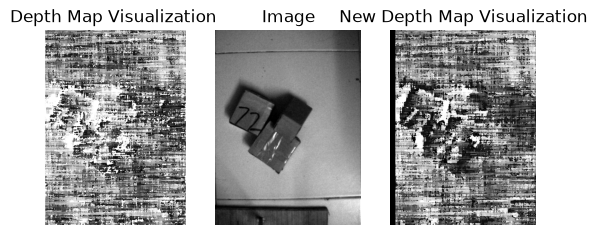

In [291]:
invalid_mask = disparity <= min_disp
disparity[invalid_mask] = np.nan

new_invalid_mask = new_disparity <= min_disp
new_disparity[invalid_mask] = np.nan

fig, ax = plt.subplots(1, 3)
ax[0].imshow(disparity, cmap='grey')
ax[0].set_title('Depth Map Visualization')
ax[0].axis('off')
ax[1].imshow(o_imgR, cmap='grey')
ax[1].set_title('Image')
ax[1].axis('off')  # Optional: Hide the pixel coordinate axes
ax[2].imshow(new_disparity, cmap='grey')
ax[2].set_title('New Depth Map Visualization')
ax[2].axis('off')

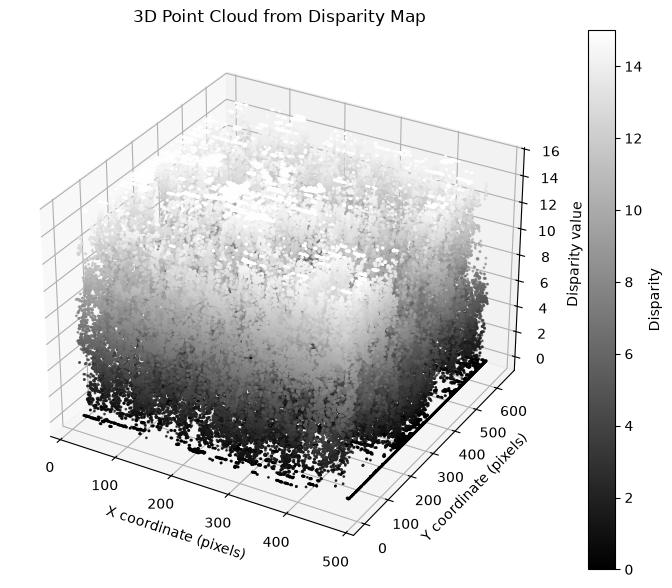

In [292]:
# Create coordinate grid
h, w = new_disparity.shape
x, y = np.meshgrid(np.arange(w), np.arange(h))

# Flatten arrays for scatter plot
x_flat = x.flatten()
y_flat = y.flatten()
z_flat = new_disparity.flatten()

# Remove invalid disparity values (e.g., negative or NaN)
mask = np.isfinite(z_flat) & (z_flat >= 0)
x_flat = x_flat[mask]
y_flat = y_flat[mask]
z_flat = z_flat[mask]

# Plot 3D point cloud
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(x_flat, y_flat, z_flat, c=z_flat, cmap='grey', s=1)

ax.set_xlabel('X coordinate (pixels)')
ax.set_ylabel('Y coordinate (pixels)')
ax.set_zlabel('Disparity value')
ax.set_title('3D Point Cloud from Disparity Map')

fig.colorbar(scatter, ax=ax, label='Disparity')
plt.show()
